<a href="https://colab.research.google.com/github/altaleb-sarah/Air-Quality-ML/blob/main/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from collections import Counter


In [ ]:
import os

print(os.listdir())

['.config', '.ipynb_checkpoints', 'sentiment.csv', 'sample_data']


In [ ]:
df = pd.read_csv("sentiment.csv")

In [ ]:
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [ ]:
df.shape

(732, 15)

In [ ]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Text', 'Sentiment', 'Timestamp', 'User',
       'Platform', 'Hashtags', 'Retweets', 'Likes', 'Country', 'Year', 'Month',
       'Day', 'Hour'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [ ]:
text_cols = ['Text', 'Sentiment', 'User', 'Platform', 'Hashtags', 'Country']

for col in text_cols:
    df[col] = df[col].str.strip().str.lower()

In [ ]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Day'] = df['Timestamp'].dt.day
df['Month'] = df['Timestamp'].dt.month
df['Year'] = df['Timestamp'].dt.year

In [ ]:
df["Retweets"] = df["Retweets"].astype(int)
df["Likes"] = df["Likes"].astype(int)

In [ ]:
df.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'], inplace=True, errors='ignore')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Text       732 non-null    object        
 1   Sentiment  732 non-null    object        
 2   Timestamp  732 non-null    datetime64[ns]
 3   User       732 non-null    object        
 4   Platform   732 non-null    object        
 5   Hashtags   732 non-null    object        
 6   Retweets   732 non-null    int64         
 7   Likes      732 non-null    int64         
 8   Country    732 non-null    object        
 9   Year       732 non-null    int32         
 10  Month      732 non-null    int32         
 11  Day        732 non-null    int32         
 12  Hour       732 non-null    int64         
dtypes: datetime64[ns](1), int32(3), int64(3), object(6)
memory usage: 65.9+ KB


In [ ]:
df.isnull().sum()

,0
Text,0
Sentiment,0
Timestamp,0
User,0
Platform,0
Hashtags,0
Retweets,0
Likes,0
Country,0
Year,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df = df.dropna().reset_index(drop=True)
print("Total missing values after handling:", df.isnull().sum().sum())

Total missing values after handling: 0


In [ ]:
df['Sentiment'].value_counts()

,count
Sentiment,
positive,45
joy,44
excitement,37
contentment,19
neutral,18
...,...
celestial wonder,1
nature's beauty,1
thrilling journey,1


In [ ]:
top_sentiments = df['Sentiment'].value_counts().head(5).index
filtered_df = df[df['Sentiment'].isin(top_sentiments)]

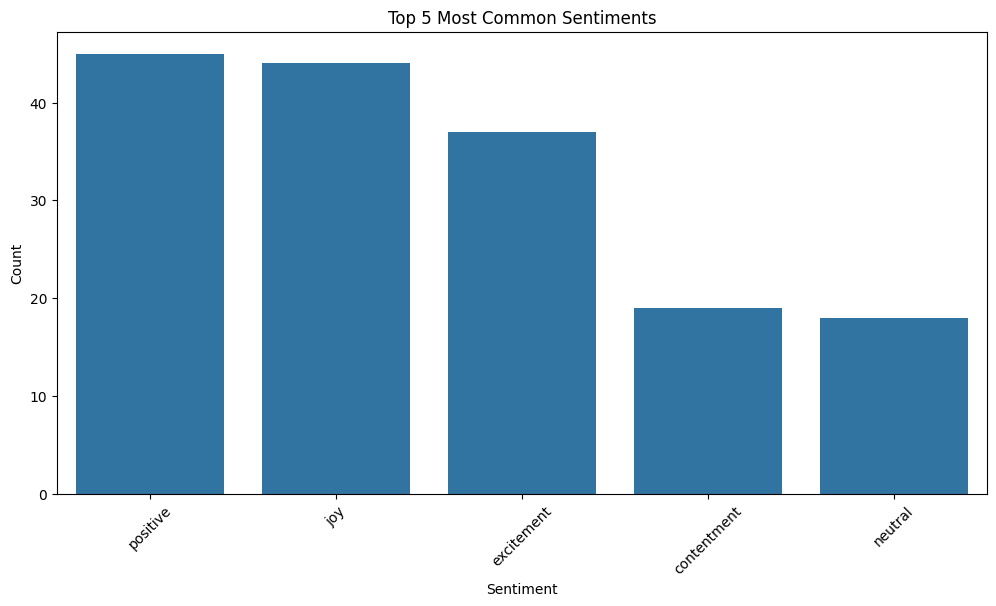

In [ ]:
#Univariate plot1
plt.figure(figsize=(12,6))

sns.countplot(
    data=filtered_df,
    x='Sentiment',
    order=top_sentiments
)

plt.title('Top 5 Most Common Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

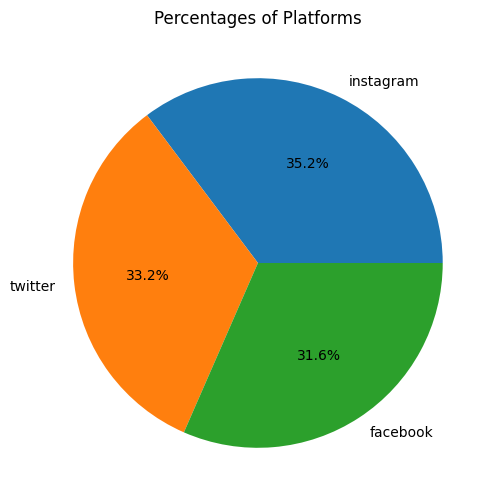

In [ ]:
#Univariate plot2
df['Platform'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(6,6)
)

plt.title('Percentages of Platforms')
plt.ylabel('')
plt.show()

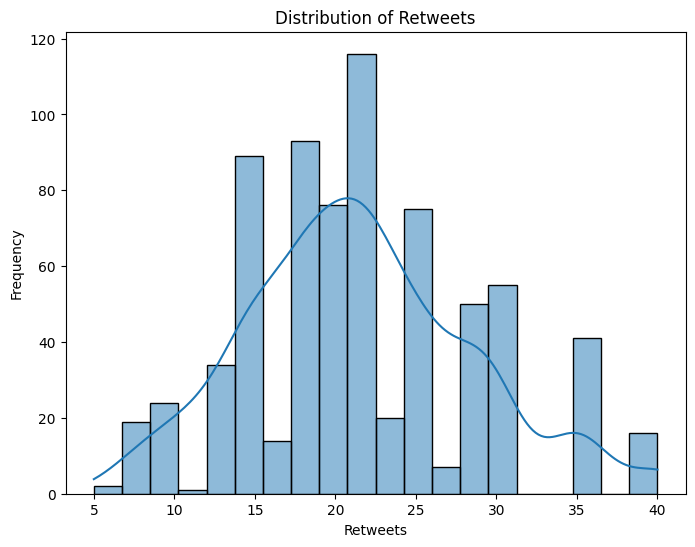

In [ ]:
#Univariate plot3
plt.figure(figsize=(8,6))

sns.histplot(df['Retweets'], bins=20, kde=True)

plt.title('Distribution of Retweets')
plt.xlabel('Retweets')
plt.ylabel('Frequency')
plt.show()

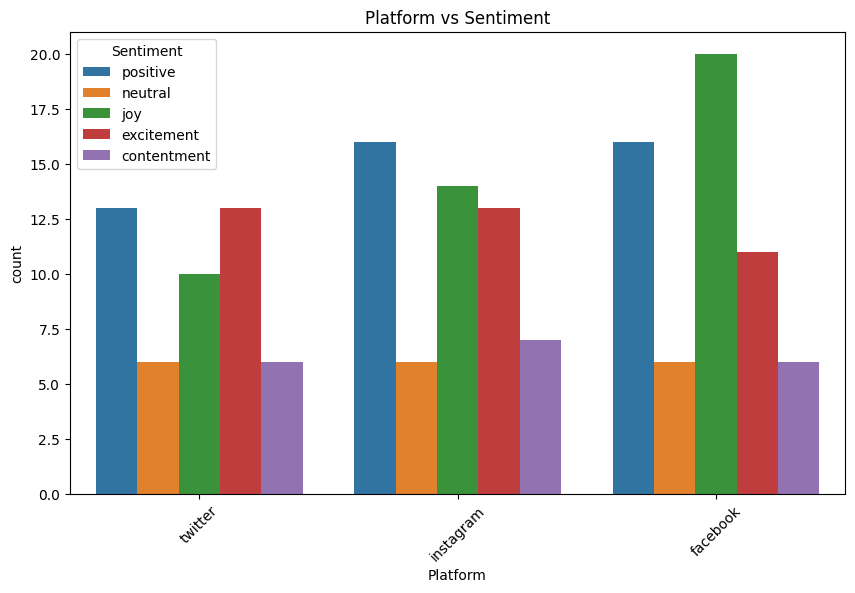

In [ ]:
# Bivariate 1
plt.figure(figsize=(10,6))
sns.countplot(data=filtered_df, x='Platform', hue='Sentiment')
plt.title('Platform vs Sentiment')
plt.xticks(rotation=45)
plt.show()


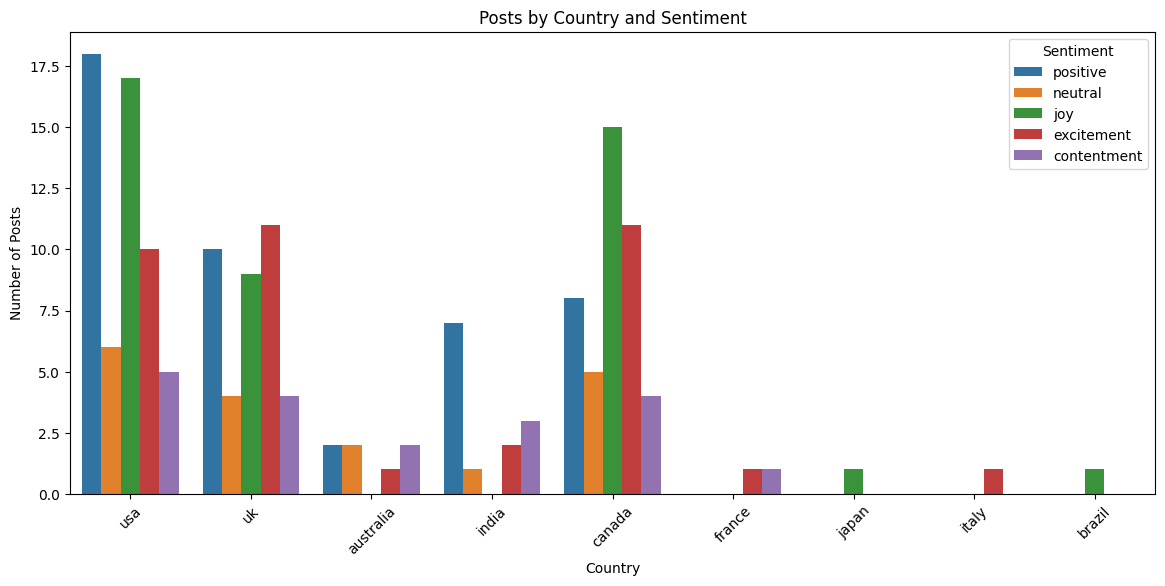

In [ ]:
# Bivariate2
top_countries = df['Country'].value_counts().head(10).index
top_sentiments = df['Sentiment'].value_counts().head(5).index

plt.figure(figsize=(14,6))
sns.countplot(
    data=df[df['Country'].isin(top_countries) & df['Sentiment'].isin(top_sentiments)],
    x='Country',
    hue='Sentiment'
)
plt.title('Posts by Country and Sentiment')
plt.xlabel('Country')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.show()

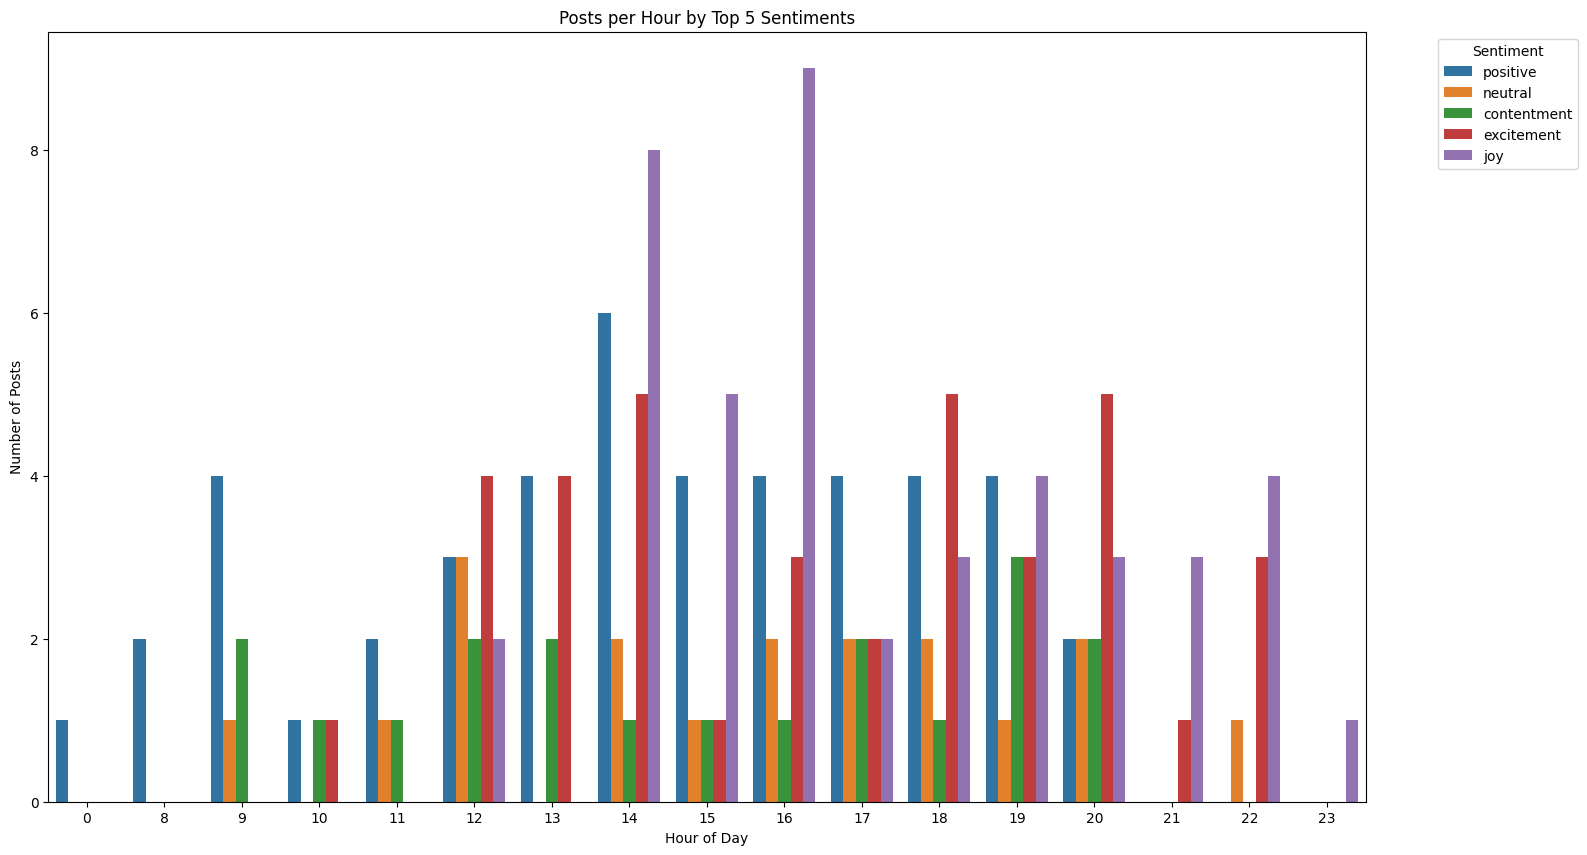

In [ ]:
#Bivariate 3
top_sentiments = df['Sentiment'].value_counts().head(5).index

plt.figure(figsize=(17,10))

sns.countplot(
    data=df[df['Sentiment'].isin(top_sentiments)],
    x='Hour',
    hue='Sentiment',

)

plt.title('Posts per Hour by Top 5 Sentiments')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Posts')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

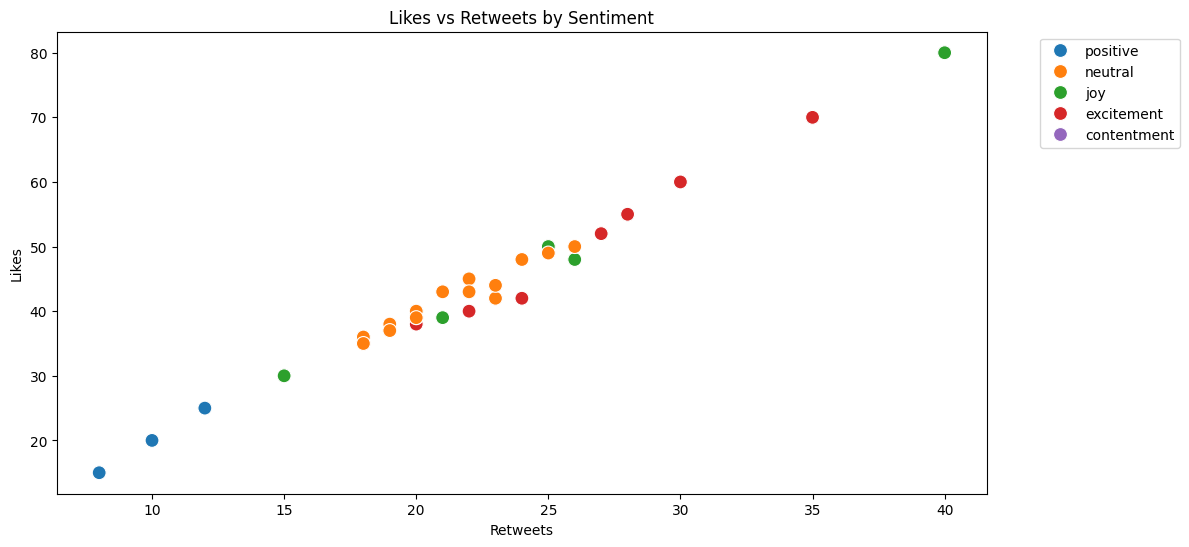

In [ ]:
# Multivariate 1
plt.figure(figsize=(12,6))
sns.scatterplot(
    data=filtered_df,
    x='Retweets',
    y='Likes',
    hue='Sentiment',
    s=100
)
plt.title('Likes vs Retweets by Sentiment')
plt.xlabel('Retweets')
plt.ylabel('Likes')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

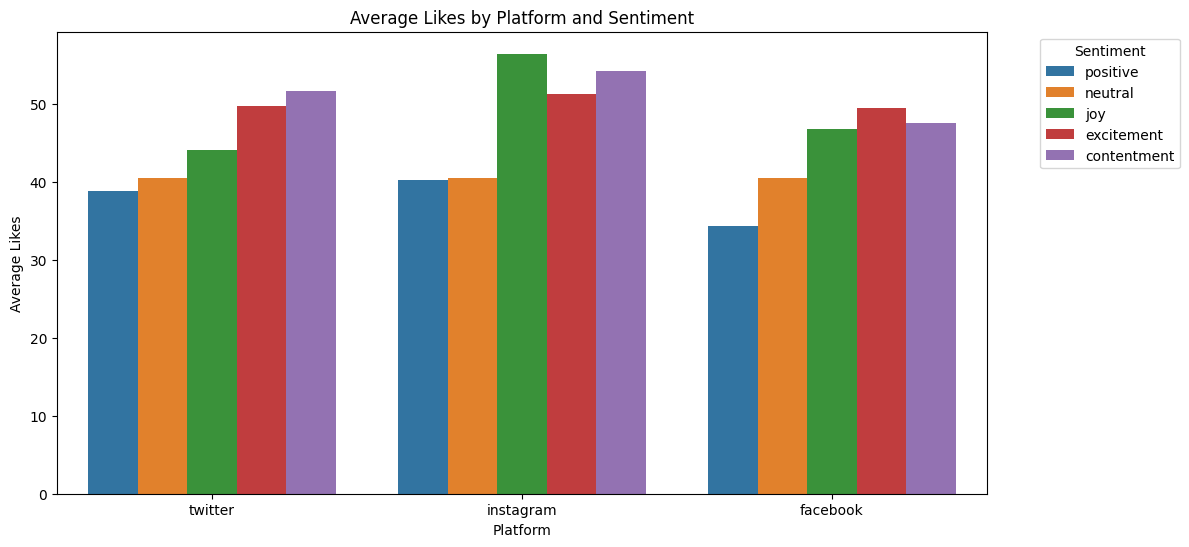

In [ ]:
#multivariate2
top_platforms = df['Platform'].value_counts().head(5).index
top_sentiments = df['Sentiment'].value_counts().head(5).index

plot_df = df[
    df['Platform'].isin(top_platforms) &
    df['Sentiment'].isin(top_sentiments)
]

plt.figure(figsize=(12,6))

sns.barplot(
    data=plot_df,
    x='Platform',
    y='Likes',
    hue='Sentiment',
    errorbar=None
)

plt.title('Average Likes by Platform and Sentiment')
plt.xlabel('Platform')
plt.ylabel('Average Likes')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

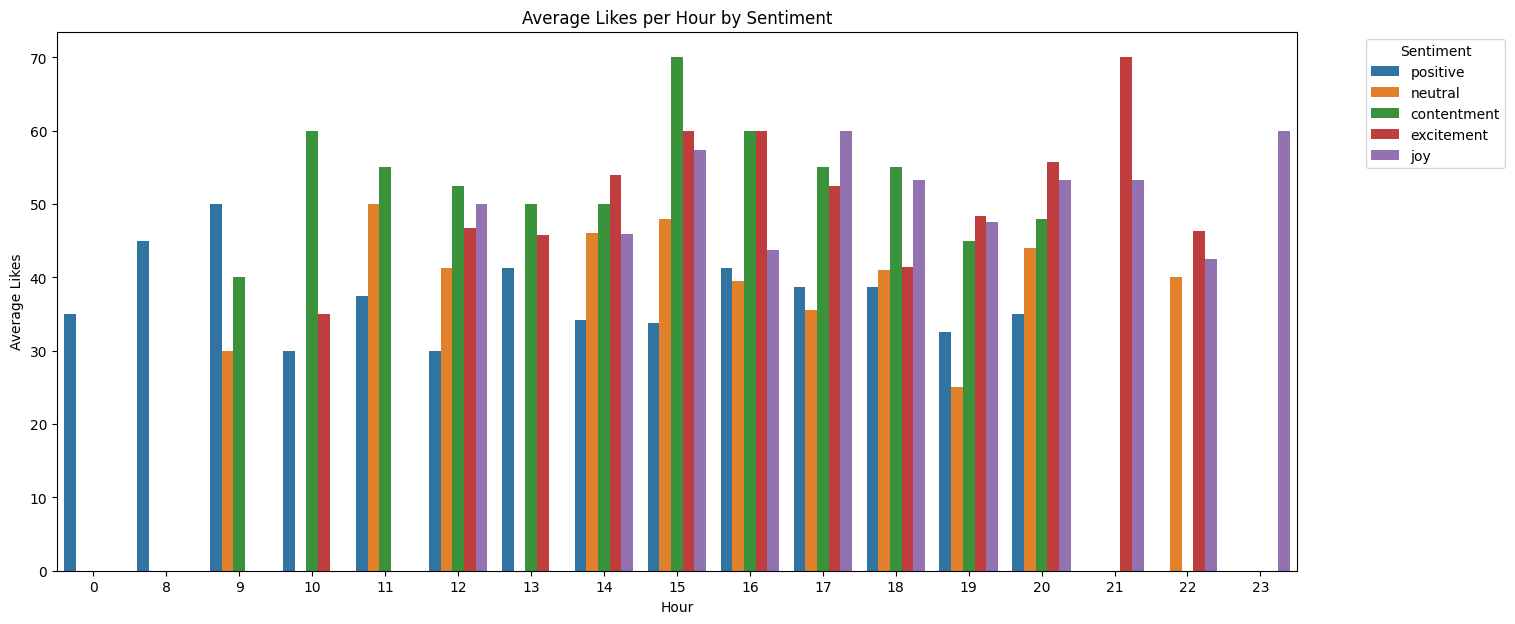

In [ ]:
# Multivariate3
top_sentiments = df['Sentiment'].value_counts().head(5).index
plot_df = df[df['Sentiment'].isin(top_sentiments)]

plt.figure(figsize=(16,7))
sns.barplot(
    data=plot_df,
    x='Hour',
    y='Likes',
    hue='Sentiment',
    errorbar=None
)
plt.title('Average Likes per Hour by Sentiment')
plt.xlabel('Hour')
plt.ylabel('Average Likes')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [ ]:
features = ['Likes', 'Retweets', 'Hour']

for col in features:
    print(f"\nFeature: {col}")

    mean = df[col].mean()
    median = df[col].median()
    std = df[col].std()
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    skewness = df[col].skew()

    print("Mean:", mean)
    print("Median:", median)
    print("Std:", std)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Skewness:", skewness)

    if skewness > 0.5:
        print("Distribution: Right-skewed")
    elif skewness < -0.5:
        print("Distribution: Left-skewed")
    else:
        print("Distribution: Approximately normal")


Feature: Likes
Mean: 42.90163934426229
Median: 43.0
Std: 14.089848390888744
Q1: 34.75
Q3: 50.0
IQR: 15.25
Lower Bound: 11.875
Upper Bound: 72.875
Skewness: 0.37813850875791316
Distribution: Approximately normal

Feature: Retweets
Mean: 21.508196721311474
Median: 22.0
Std: 7.061286414470437
Q1: 17.75
Q3: 25.0
IQR: 7.25
Lower Bound: 6.875
Upper Bound: 35.875
Skewness: 0.36341226758224254
Distribution: Approximately normal

Feature: Hour
Mean: 15.521857923497267
Median: 16.0
Std: 4.113414422635385
Q1: 13.0
Q3: 19.0
IQR: 6.0
Lower Bound: 4.0
Upper Bound: 28.0
Skewness: -0.4360026627213562
Distribution: Approximately normal


In [ ]:
# Remove outliers from all numeric features

numeric_cols = df.select_dtypes(include='number').columns

before = df.shape

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

df = df.reset_index(drop=True)

print("Before removing outliers:", before)
print("After removing outliers:", df.shape)

Before removing outliers: (732, 13)
After removing outliers: (698, 13)


In [ ]:
numeric_features = df.select_dtypes(include='number').columns

for col in numeric_features:

    skewness = df[col].skew()

    print(f"\nFeature: {col}")
    print("Skewness:", skewness)

    if skewness > 0.5:
        print("Distribution: Right-skewed")

    elif skewness < -0.5:
        print("Distribution: Left-skewed")

    else:
        print("Distribution: Approximately Normal")


Feature: Retweets
Skewness: 0.1709391509885573
Distribution: Approximately Normal

Feature: Likes
Skewness: 0.1839142007396888
Distribution: Approximately Normal

Feature: Year
Skewness: -0.7806779805569555
Distribution: Left-skewed

Feature: Month
Skewness: 0.01862256523616893
Distribution: Approximately Normal

Feature: Day
Skewness: 0.043071041860010754
Distribution: Approximately Normal

Feature: Hour
Skewness: -0.28896651613313423
Distribution: Approximately Normal


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["Text"],
    df["Sentiment"],
    test_size=0.3,
    random_state=50
)

vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = LinearSVC()
model.fit(X_train_tfidf, y_train)

LinearSVC()

In [ ]:
y_train_pred = model.predict(X_train_tfidf)
y_test_pred = model.predict(X_test_tfidf)

train_accuracy = accuracy_score(y_train, y_train_pred)
train_error = 1 - train_accuracy

test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1 - test_accuracy

print("Training Accuracy:", train_accuracy)
print("Training Error Rate:", train_error)

print("Test Accuracy:", test_accuracy)
print("Test Error Rate:", test_error)

Training Accuracy: 1.0
Training Error Rate: 0.0
Test Accuracy: 0.5285714285714286
Test Error Rate: 0.4714285714285714
